# Tugas - Klasifikasi dengan Decision Tree

| Nama | NRP |
|---|---|
|Fauzan Tamma Harish Kunfaza|5054251035|

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model Decision Tree Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja Decision Tree secara praktik, khususnya:
1. Perbedaan hasil antara kriteria split Gini Impurity dan Entropy
2. Pengaruh regularisasi (max_depth) terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Decision Tree dengan kriteria Gini dan Entropy.
   - Lakukan eksperimen regularisasi dengan variasi nilai max_depth.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

sns.set_style("whitegrid")
pd.set_option('display.max_columns', 10)

In [2]:
# Load dataset dan tampilkan informasi dasar
df = pd.read_csv('bankruptcy.csv')
df.columns = [c.strip() for c in df.columns]  # rapikan nama kolom

print("Ukuran dataset:", df.shape)
print("\nInfo tipe data (ringkas):")
print(df.dtypes.value_counts())
print("\nJumlah missing value total:", df.isnull().sum().sum())
print("\nStatistik deskriptif (5 kolom pertama):")
print(df.iloc[:, :5].describe().round(3))

Ukuran dataset: (6819, 96)

Info tipe data (ringkas):
float64    93
int64       3
Name: count, dtype: int64

Jumlah missing value total: 0

Statistik deskriptif (5 kolom pertama):
       Bankrupt?  ROA(C) before interest and depreciation before interest  \
count   6819.000                                           6819.000         
mean       0.032                                              0.505         
std        0.177                                              0.061         
min        0.000                                              0.000         
25%        0.000                                              0.477         
50%        0.000                                              0.503         
75%        0.000                                              0.536         
max        1.000                                              1.000         

       ROA(A) before interest and % after tax  \
count                                6819.000   
mean                        

Distribusi kelas target (Bankrupt?):
           jumlah  persen (%)
Bankrupt?                    
0            6599       96.77
1             220        3.23

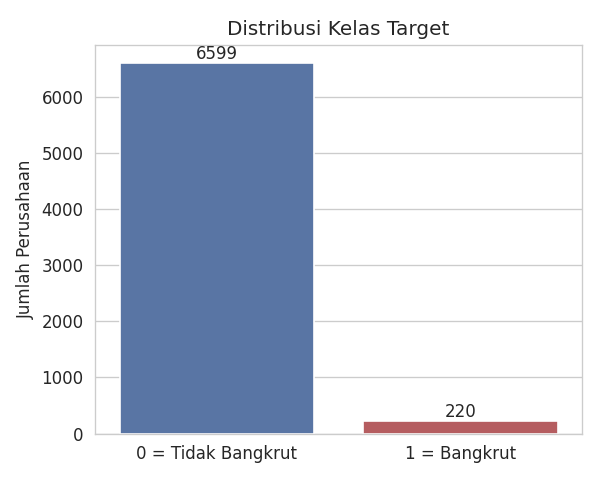


-> Dataset sangat imbalanced: kelas 1 (Bangkrut) hanya 3.23% dari total data.

In [3]:
# Tampilkan distribusi kelas target dalam bentuk bar plot
target_counts = df['Bankrupt?'].value_counts().sort_index()
pct = (target_counts / target_counts.sum() * 100).round(2)
print("Distribusi kelas target (Bankrupt?):")
print(pd.DataFrame({'jumlah': target_counts, 'persen (%)': pct}))

plt.figure(figsize=(5,4))
ax = sns.countplot(x='Bankrupt?', data=df, hue='Bankrupt?', palette=['#4C72B0','#C44E52'], legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels(['0 = Tidak Bangkrut','1 = Bangkrut'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
ax.set_title("Distribusi Kelas Target")
ax.set_xlabel(""); ax.set_ylabel("Jumlah Perusahaan")
plt.tight_layout(); plt.show()

print(f"\n-> Dataset sangat imbalanced: kelas 1 (Bangkrut) hanya {pct[1]}% dari total data.")

6 fitur dengan korelasi absolut tertinggi terhadap target:
Net Income to Total Assets                                 0.3155
ROA(A) before interest and % after tax                     0.2829
ROA(B) before interest and depreciation after tax          0.2731
ROA(C) before interest and depreciation before interest    0.2608
Net worth/Assets                                           0.2502
Debt ratio %                                               0.2502
dtype: float64

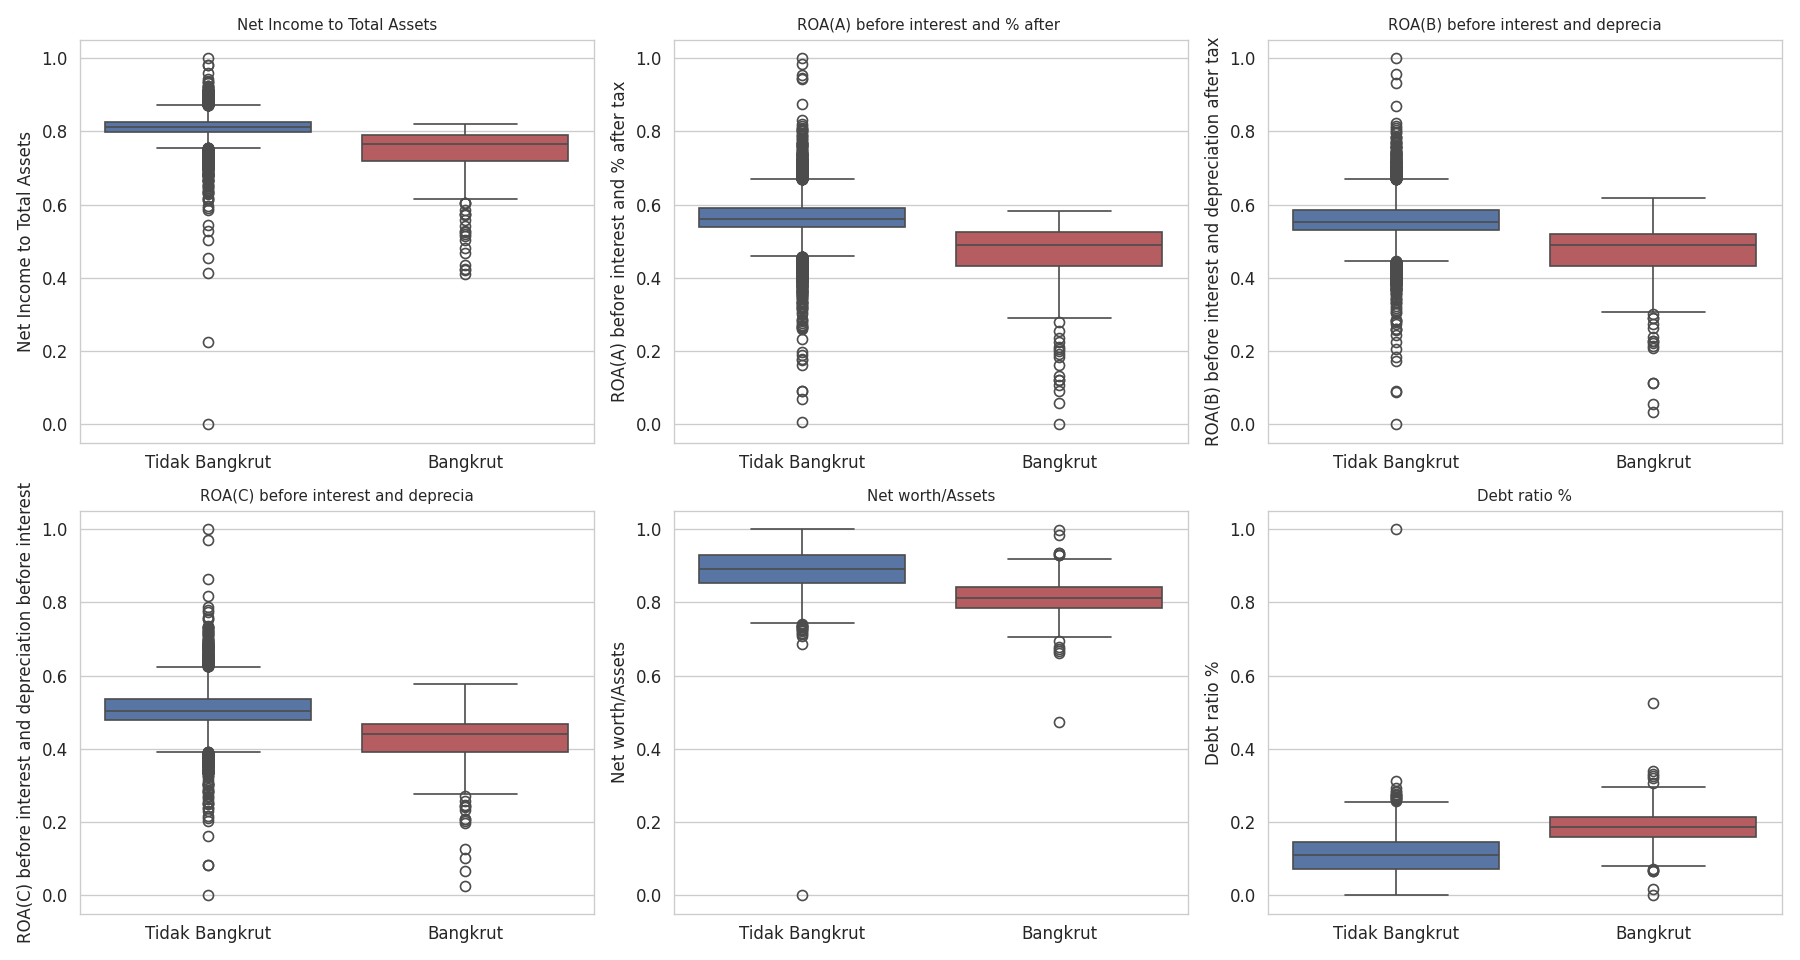

In [4]:
# Tampilkan distribusi fitur (boxplot), dibedakan berdasarkan kelas target
# Dipilih 6 fitur dengan korelasi absolut tertinggi terhadap target agar mudah dibaca
corr_with_target = df.drop(columns=['Bankrupt?']).corrwith(df['Bankrupt?']).abs().sort_values(ascending=False)
top6 = corr_with_target.head(6).index.tolist()
print("6 fitur dengan korelasi absolut tertinggi terhadap target:")
print(corr_with_target.head(6).round(4))

fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.flat, top6):
    sns.boxplot(x='Bankrupt?', y=col, data=df, hue='Bankrupt?', palette=['#4C72B0','#C44E52'], legend=False, ax=ax)
    ax.set_xticks([0,1]); ax.set_xticklabels(['Tidak Bangkrut','Bangkrut'])
    ax.set_title(col[:35], fontsize=9)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan

Heatmap korelasi 12 fitur teratas terhadap target berhasil dibuat.

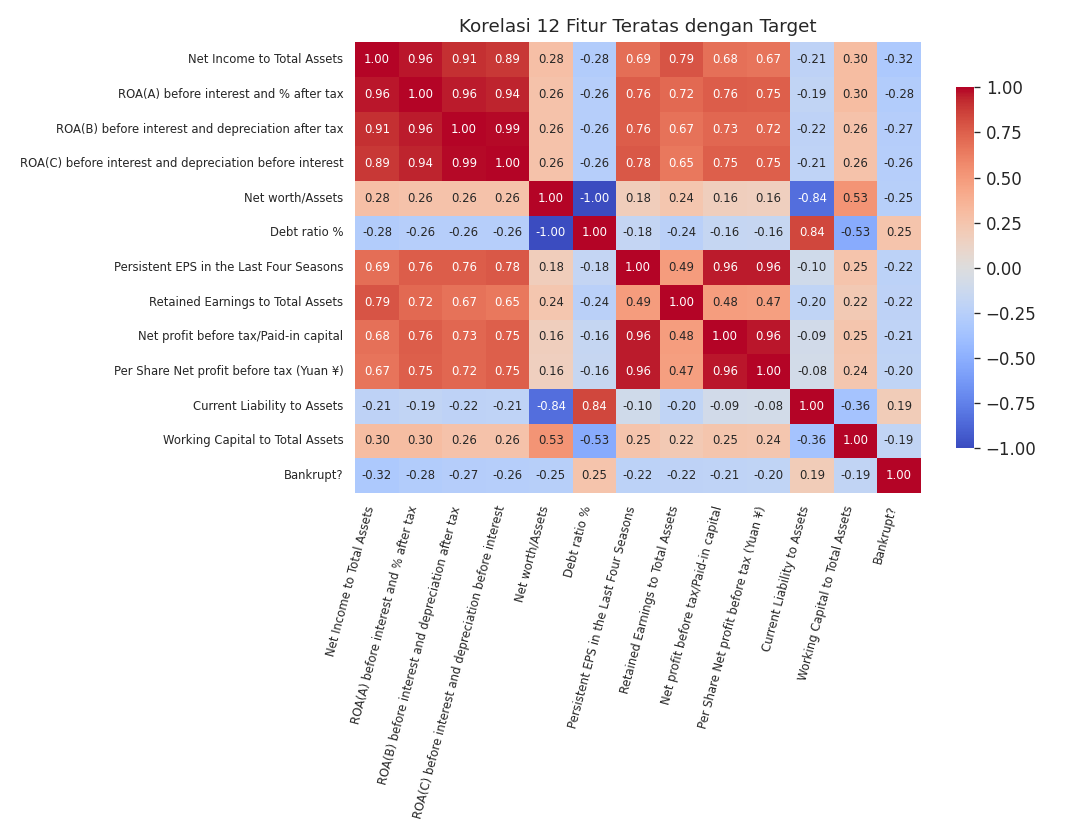

In [5]:
# EDA tambahan: heatmap korelasi 12 fitur teratas terhadap target
top_features = corr_with_target.head(12).index.tolist()
corr_matrix = df[top_features + ['Bankrupt?']].corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'shrink':.8},
            annot_kws={"size":7})
plt.xticks(fontsize=7, rotation=75, ha='right'); plt.yticks(fontsize=7)
plt.title("Korelasi 12 Fitur Teratas dengan Target", fontsize=11)
plt.tight_layout(); plt.show()

# 2. Preprocessing

In [6]:
# Tangani missing value (jika ada)
missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing) == 0:
    print("Tidak ditemukan missing value pada dataset ini, sehingga tidak diperlukan imputasi.")
else:
    print(missing)

Tidak ditemukan missing value pada dataset ini, sehingga tidak diperlukan imputasi.

In [7]:
# Cek fitur kategorikal untuk encoding
non_numeric = df.select_dtypes(exclude=[np.number]).columns.tolist()
print("Kolom non-numerik:", non_numeric if non_numeric else "Tidak ada")
print("Seluruh fitur pada dataset ini sudah berbentuk numerik (hasil rasio keuangan),")
print("sehingga tidak diperlukan proses encoding kategorikal.")

Kolom non-numerik: Tidak ada
Seluruh fitur pada dataset ini sudah berbentuk numerik (hasil rasio keuangan),
sehingga tidak diperlukan proses encoding kategorikal.

In [8]:
# Pisahkan fitur (X) dan target (y), lalu bagi train/test 80:20 dengan stratify
X = df.drop(columns=['Bankrupt?'])
y = df['Bankrupt?']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Ukuran X_train:", X_train.shape, " X_test:", X_test.shape)
print("\nProporsi kelas y_train:")
print((y_train.value_counts(normalize=True)*100).round(2))
print("\nProporsi kelas y_test:")
print((y_test.value_counts(normalize=True)*100).round(2))

Ukuran X_train: (5455, 95)  X_test: (1364, 95)

Proporsi kelas y_train:
Bankrupt?
0    96.77
1     3.23
Name: proportion, dtype: float64

Proporsi kelas y_test:
Bankrupt?
0    96.77
1     3.23
Name: proportion, dtype: float64

**Catatan penting:** Decision Tree tidak memerlukan feature scaling (StandardScaler/MinMaxScaler). Split pada Decision Tree dilakukan berdasarkan threshold per fitur satu per satu, bukan berdasarkan jarak antar titik seperti pada KNN atau SVM. Jadi tidak dilakukan scaling pada tahap ini.

# 3. Eksperimen Model

## 3.1 Decision Tree dengan Kriteria Gini

Gini Impurity adalah kriteria default pada DecisionTreeClassifier di scikit-learn. Kriteria ini mengukur peluang kesalahan klasifikasi jika sebuah sampel dipilih secara acak dari suatu node.

In [9]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='gini'
dt_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_gini.fit(X_train, y_train)
print("Model Decision Tree (criterion='gini') berhasil dilatih.")
print("Kedalaman pohon (unbounded):", dt_gini.get_depth(), " | Jumlah leaf:", dt_gini.get_n_leaves())

Model Decision Tree (criterion='gini') berhasil dilatih.
Kedalaman pohon (unbounded): 20  | Jumlah leaf: 124

In [10]:
# Prediksi pada test set
y_pred_gini = dt_gini.predict(X_test)
print("Prediksi pada test set selesai. Contoh 10 prediksi pertama:", y_pred_gini[:10])

Prediksi pada test set selesai. Contoh 10 prediksi pertama: [0 0 0 0 0 1 0 0 0 0]

## 3.2 Decision Tree dengan Kriteria Entropy

Entropy (Information Gain) adalah kriteria alternatif yang mengukur tingkat ketidakpastian distribusi kelas pada suatu node.

In [11]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='entropy'
# Hyperparameter lain dibuat sama seperti model Gini agar perbandingan adil
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_entropy.fit(X_train, y_train)
print("Model Decision Tree (criterion='entropy') berhasil dilatih.")
print("Kedalaman pohon (unbounded):", dt_entropy.get_depth(), " | Jumlah leaf:", dt_entropy.get_n_leaves())

Model Decision Tree (criterion='entropy') berhasil dilatih.
Kedalaman pohon (unbounded): 17  | Jumlah leaf: 99

In [12]:
# Prediksi pada test set
y_pred_entropy = dt_entropy.predict(X_test)
print("Prediksi pada test set selesai. Contoh 10 prediksi pertama:", y_pred_entropy[:10])

Prediksi pada test set selesai. Contoh 10 prediksi pertama: [0 0 0 0 0 0 0 0 0 0]

## 3.3 Eksperimen Regularisasi: Pengaruh max_depth terhadap Overfitting

Decision Tree yang dibiarkan tumbuh tanpa batas cenderung overfitting terhadap data training. Pada bagian ini diamati bagaimana perubahan nilai max_depth memengaruhi akurasi training dan testing.

In [13]:
# Latih beberapa model dengan variasi max_depth (kriteria gini dari eksperimen terbaik di atas)
depth_values = [1, 2, 3, 5, 10, None]
results = []
for d in depth_values:
    m = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, m.predict(X_train))
    test_acc = accuracy_score(y_test, m.predict(X_test))
    results.append({'max_depth': 'None' if d is None else d, 'train_acc': train_acc, 'test_acc': test_acc})

depth_df = pd.DataFrame(results)
print(depth_df.round(4))

  max_depth  train_acc  test_acc
0         1     0.9677    0.9677
1         2     0.9699    0.9699
2         3     0.9723    0.9699
3         5     0.9775    0.9685
4        10     0.9947    0.9604
5      None     1.0000    0.9611

In [14]:
# Tabel akurasi train vs test untuk tiap nilai max_depth
print("Tabel akurasi train vs test per nilai max_depth:")
print(depth_df.round(4).to_string(index=False))

Tabel akurasi train vs test per nilai max_depth:
max_depth  train_acc  test_acc
        1     0.9677    0.9677
        2     0.9699    0.9699
        3     0.9723    0.9699
        5     0.9775    0.9685
       10     0.9947    0.9604
     None     1.0000    0.9611

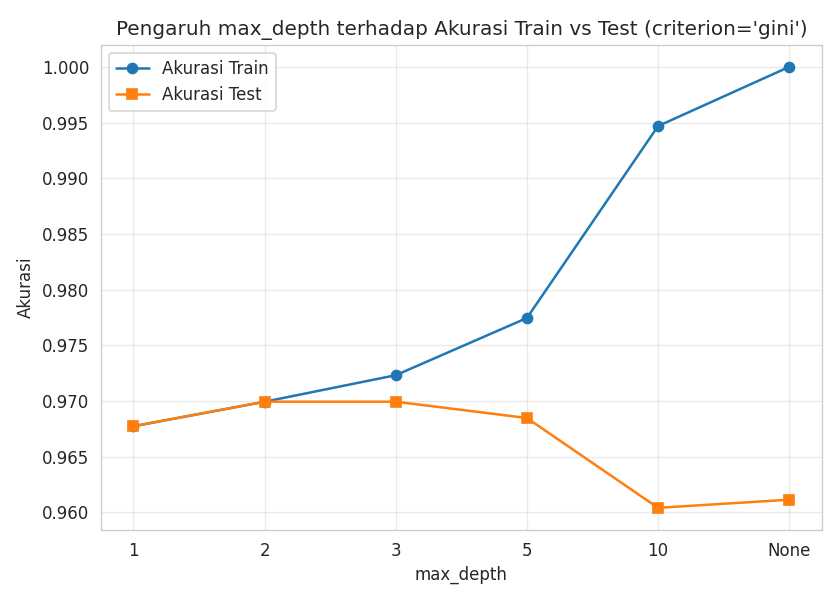

Selisih (gap) akurasi train - test per max_depth:
max_depth     gap
        1 -0.0000
        2 -0.0000
        3  0.0024
        5  0.0090
       10  0.0343
     None  0.0389

In [15]:
# Plot grafik akurasi training vs testing terhadap max_depth
x_labels = [str(v) for v in depth_df['max_depth']]
plt.figure(figsize=(7,5))
plt.plot(x_labels, depth_df['train_acc'], marker='o', label='Akurasi Train')
plt.plot(x_labels, depth_df['test_acc'], marker='s', label='Akurasi Test')
plt.xlabel("max_depth"); plt.ylabel("Akurasi")
plt.title("Pengaruh max_depth terhadap Akurasi Train vs Test (criterion='gini')")
plt.legend(); plt.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

gap = (depth_df['train_acc'] - depth_df['test_acc']).round(4)
print("Selisih (gap) akurasi train - test per max_depth:")
print(pd.DataFrame({'max_depth': x_labels, 'gap': gap}).to_string(index=False))

# 4. Evaluasi Model

In [16]:
# Metrik evaluasi (Accuracy, Precision, Recall, F1) untuk model Gini dan Entropy
# Karena dataset sangat imbalanced, ditampilkan juga metrik khusus untuk kelas 'Bangkrut' (kelas minoritas)
def get_metrics(y_true, y_pred, label):
    return {
        'Model': label,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (weighted)': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall (weighted)': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1-Score (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Precision (kelas Bangkrut)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (kelas Bangkrut)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1 (kelas Bangkrut)': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }

metrics_df = pd.DataFrame([
    get_metrics(y_test, y_pred_gini, 'Gini'),
    get_metrics(y_test, y_pred_entropy, 'Entropy'),
]).set_index('Model')
metrics_df.round(4).T

Model                         Gini  Entropy
Accuracy                    0.9611   0.9641
Precision (weighted)        0.9616   0.9621
Recall (weighted)           0.9611   0.9641
F1-Score (weighted)         0.9614   0.9630
Precision (kelas Bangkrut)  0.4000   0.4359
Recall (kelas Bangkrut)     0.4091   0.3864
F1 (kelas Bangkrut)         0.4045   0.4096

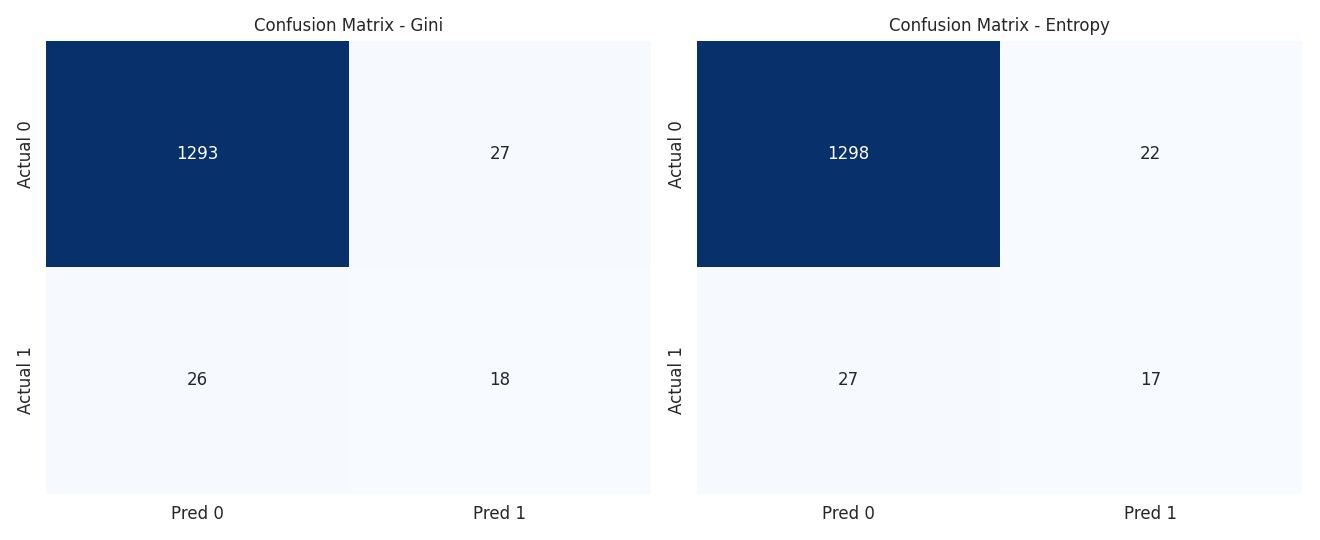

Confusion matrix Gini:
 [[1293   27]
 [  26   18]]
Confusion matrix Entropy:
 [[1298   22]
 [  27   17]]

In [17]:
# Confusion Matrix untuk model Gini dan Entropy (heatmap, satu baris subplot)
cm_gini = confusion_matrix(y_test, y_pred_gini)
cm_entropy = confusion_matrix(y_test, y_pred_entropy)

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
for ax, cm, title in zip(axes, [cm_gini, cm_entropy], ['Confusion Matrix - Gini', 'Confusion Matrix - Entropy']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Pred 0','Pred 1'], yticklabels=['Actual 0','Actual 1'])
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

Model dengan F1-Score (weighted) tertinggi pada test set: Entropy
Accuracy                      0.9641
Precision (weighted)          0.9621
Recall (weighted)             0.9641
F1-Score (weighted)           0.9630
Precision (kelas Bangkrut)    0.4359
Recall (kelas Bangkrut)       0.3864
F1 (kelas Bangkrut)           0.4096
Name: Entropy, dtype: float64

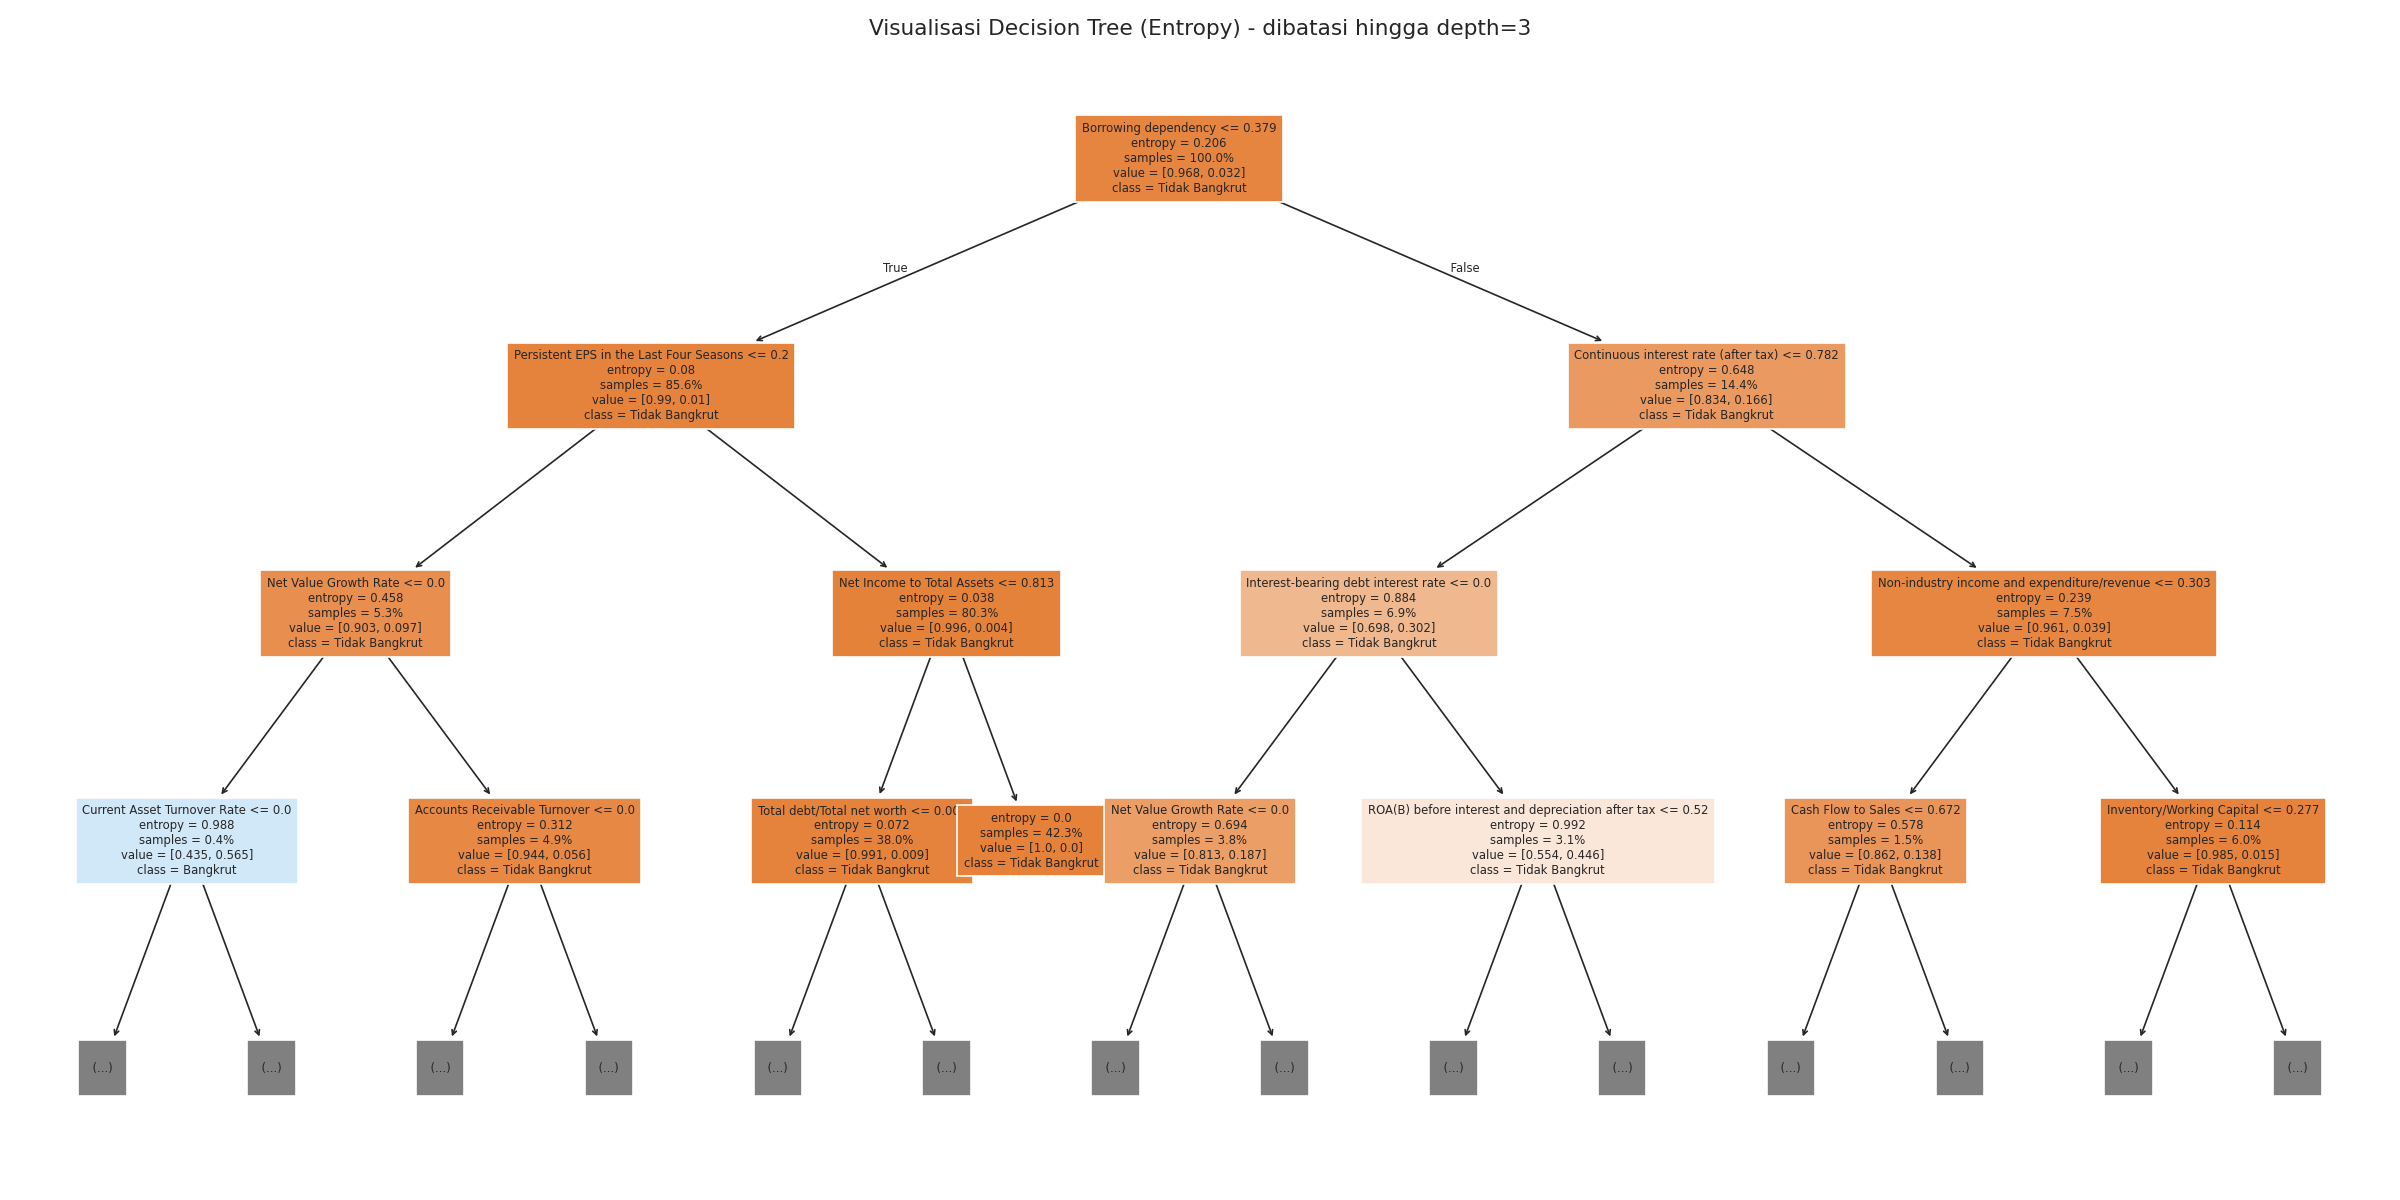

In [18]:
# Visualisasikan struktur Decision Tree untuk model dengan performa terbaik (dibatasi depth=3 agar terbaca)
best_label = metrics_df['F1-Score (weighted)'].idxmax()
best_model = dt_gini if best_label == 'Gini' else dt_entropy
print(f"Model dengan F1-Score (weighted) tertinggi pada test set: {best_label}")
print(metrics_df.loc[best_label].round(4))

plt.figure(figsize=(20,10))
plot_tree(best_model, max_depth=3, feature_names=X.columns, class_names=['Tidak Bangkrut','Bangkrut'],
          filled=True, fontsize=7, proportion=True)
plt.title(f"Visualisasi Decision Tree ({best_label}) - dibatasi hingga depth=3", fontsize=13)
plt.tight_layout(); plt.show()

15 fitur paling berpengaruh pada model Entropy:
Borrowing dependency                           0.2221
Continuous interest rate (after tax)           0.0758
Persistent EPS in the Last Four Seasons        0.0635
Net Value Growth Rate                          0.0517
Quick Ratio                                    0.0298
Operating Profit Growth Rate                   0.0270
Net Income to Total Assets                     0.0247
Interest-bearing debt interest rate            0.0242
Operating Expense Rate                         0.0225
Non-industry income and expenditure/revenue    0.0189
Working capitcal Turnover Rate                 0.0177
No-credit Interval                             0.0170
Degree of Financial Leverage (DFL)             0.0158
Cash/Total Assets                              0.0151
Inventory/Working Capital                      0.0145
dtype: float64

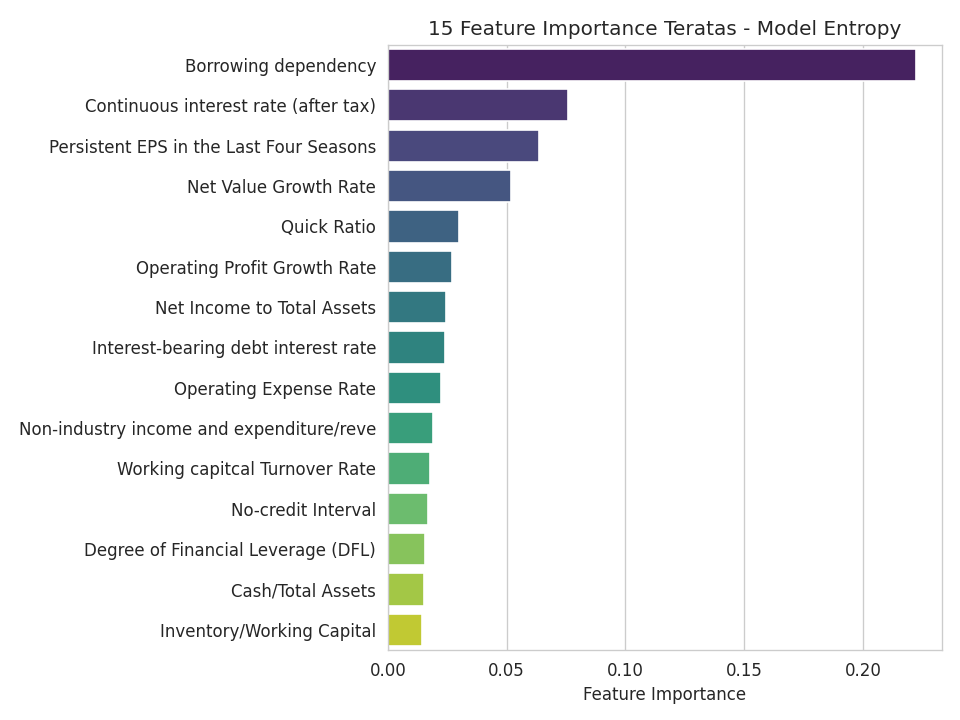

In [19]:
# Feature importance dari model terbaik (bar chart horizontal, top 15)
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
top15 = importances.head(15)
print(f"15 fitur paling berpengaruh pada model {best_label}:")
print(top15.round(4))

plt.figure(figsize=(8,6))
sns.barplot(x=top15.values, y=[f[:40] for f in top15.index], hue=[f[:40] for f in top15.index],
            palette="viridis", legend=False)
plt.xlabel("Feature Importance"); plt.ylabel("")
plt.title(f"15 Feature Importance Teratas - Model {best_label}")
plt.tight_layout(); plt.show()

# 5. Analisis

### Perbandingan Gini vs Entropy

Secara keseluruhan performa kedua kriteria split **hampir setara**. Pada model tanpa batas kedalaman,
Gini menghasilkan Accuracy 0,9611 dan F1-Score (weighted) 0,9614, sedangkan Entropy sedikit lebih unggul
dengan Accuracy 0,9641 dan F1-Score (weighted) 0,9630. Untuk kelas minoritas (Bangkrut), Entropy juga
unggul tipis pada precision (0,436 vs 0,400) meski recall-nya sedikit lebih rendah (0,386 vs 0,409).

Perbedaan ini tidak signifikan secara praktis. Hal ini wajar karena Gini Impurity dan Entropy
mengukur "ketidakmurnian" node dengan formula yang berbeda, tetapi keduanya cenderung memilih split
yang serupa pada mayoritas kasus — kurva keduanya berbentuk cekung dan mencapai nilai maksimum saat
distribusi kelas 50:50, sehingga hasil pemilihan fitur/split terbaik jarang jauh berbeda. Perbedaan
kecil yang muncul di sini kemungkinan besar karena Entropy sedikit lebih sensitif terhadap
ketidakseimbangan kelas (memberi "penalti" lebih besar pada node yang tidak murni), sehingga pada
dataset yang sangat imbalanced seperti ini menghasilkan struktur pohon yang sedikit lebih ringkas
(depth 17, 99 leaf) dibanding Gini (depth 20, 124 leaf).

### Eksperimen Regularisasi (max_depth)

Dari tabel dan grafik akurasi train vs test terlihat pola overfitting yang jelas:

| max_depth | Train Acc | Test Acc | Gap |
|---|---|---|---|
| 1 | 0,9677 | 0,9677 | 0,0000 |
| 2 | 0,9699 | 0,9699 | 0,0000 |
| 3 | 0,9723 | 0,9699 | 0,0024 |
| 5 | 0,9775 | 0,9685 | 0,0090 |
| 10 | 0,9947 | 0,9604 | 0,0343 |
| None | 1,0000 | 0,9611 | 0,0389 |

Hingga `max_depth=3`, akurasi train dan test masih naik bersama dan gap-nya sangat kecil (model masih
*underfitting/well-fit*). Mulai `max_depth=5`, gap mulai melebar, dan pada `max_depth=10` serta `None`
gejala overfitting sudah jelas: akurasi training terus naik hingga mencapai 100% pada model tanpa
batas kedalaman, sementara akurasi testing justru **stagnan bahkan sedikit menurun** (dari 0,9699 di
depth 3 turun ke 0,9604–0,9611 di depth 10 dan None). Ini adalah ciri khas overfitting — model mulai
menghafal noise/detail spesifik data training alih-alih mempelajari pola umum yang bisa digeneralisasi.
Titik ideal pada eksperimen ini ada di sekitar `max_depth=2–3`, di mana model sudah cukup akurat namun
gap train-test masih minimal.

### Fitur Paling Berpengaruh

Berdasarkan feature importance dari model terbaik (Entropy), fitur yang paling dominan adalah
**Borrowing dependency** (importance ≈ 0,222, jauh di atas fitur lain), diikuti oleh **Continuous
interest rate (after tax)** (≈ 0,076) dan **Persistent EPS in the Last Four Seasons** (≈ 0,064).
Fitur-fitur ini secara konsep memang masuk akal sebagai indikator risiko kebangkrutan: tingkat
ketergantungan pada utang (borrowing dependency) yang tinggi mencerminkan beban finansial yang berat,
sementara EPS yang konsisten rendah mencerminkan profitabilitas yang lemah — keduanya adalah sinyal
klasik kesulitan keuangan perusahaan.

# 6. Kesimpulan dan Saran

Model Decision Tree cukup mampu mengklasifikasikan status kebangkrutan perusahaan dengan akurasi
di atas 96%, namun karena dataset sangat imbalanced (hanya 3,23% kelas Bangkrut), akurasi tinggi ini
tidak sepenuhnya mencerminkan kemampuan model mendeteksi perusahaan yang benar-benar bangkrut —
terlihat dari recall kelas Bangkrut yang masih rendah (≈ 0,39–0,41). Kriteria split Gini dan Entropy
memberi hasil yang hampir setara, dengan Entropy sedikit lebih baik pada kasus ini. Eksperimen
`max_depth` menunjukkan bahwa membatasi kedalaman pohon di sekitar 2–3 sudah cukup untuk mendapatkan
performa terbaik pada data uji sekaligus mencegah overfitting yang jelas terlihat saat pohon dibiarkan
tumbuh tanpa batas.

**Saran untuk eksperimen selanjutnya:**
- Menangani ketidakseimbangan kelas secara eksplisit, misalnya dengan `class_weight='balanced'`,
  oversampling (SMOTE), atau undersampling, agar recall kelas Bangkrut meningkat.
- Melakukan pruning dengan `ccp_alpha` sebagai alternatif regularisasi selain `max_depth`.
- Mencoba variasi hyperparameter lain seperti `min_samples_leaf` dan `min_samples_split`.
- Membandingkan Decision Tree dengan model lain seperti Random Forest atau Gradient Boosting yang
  umumnya lebih robust terhadap overfitting dan data imbalanced.
- Melakukan feature selection agar model lebih sederhana dan mudah diinterpretasi, mengingat dataset
  memiliki 95 fitur dengan kemungkinan multikolinearitas antar rasio keuangan.